![ERA5-Land Validation.png](<attachment:ERA5-Land Validation.png>)
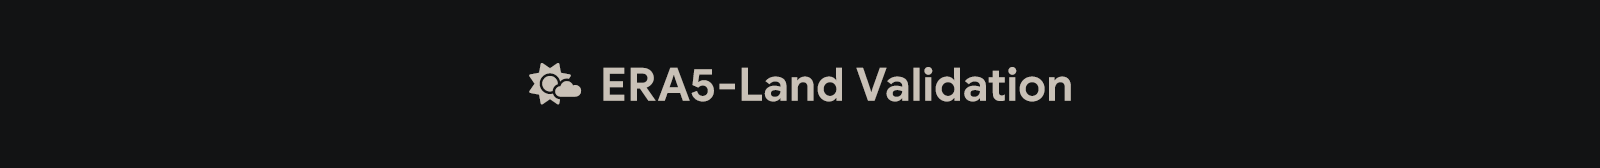

| | |
|:--|:--|
| **Authors** | Ali Rezaali & Parastoo Pilehforooshha |
| **Code Archive** | Zenodo · [10.5281/zenodo.22865045](https://doi.org/10.5281/zenodo.22865045) |
| **Data Archive** | Zenodo · [10.5281/zenodo.22723885](https://doi.org/10.5281/zenodo.22723885) |
| **Notebook Version** | 1.0.0 |
| **Runtime** | Google Colab (Python 3) |

#### **How To Cite**

**UC4D (Code):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube Framework (Version 1.0) [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.22865045

**UC4D (Dataset):**

> Rezaali, A., & Pilehforooshha, P. (2026). UC4D: Urban Climate 4D Data Cube (Version 1.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.22723885

---

#### **Overview**

This notebook renders the validation figures used to assess the ERA5-Land downscaling and bias-correction pipeline for Tehran and Singapore: a season × pathway heatmap per variable. It reads the per-season CSVs produced upstream (§2) and writes the figures back into the same per-city folder tree, identical within a fixed environment.

| Step | Section | What Happens |
|:--:|:--|:--|
| 1 | §1 | Environment: mount Google Drive, set the EB Garamond style. |
| 2 | §2 | Configuration: input/output paths, seasons per city, pathways per variable, metric directions. |
| 3 | §3 | Loaders and metrics: read the per-season CSVs, assemble (Obs, Pred) pairs per pathway. |
| 4 | §4 | Plot helpers: colormap selection, pixel-exact axis placement, colorbar ticks. |
| 5 | §5 | Season × pathway heatmaps (one per city/variable, Full + Clipped). |
| 6 | §6 | Execution: run every figure for every configured city. |

#### **Products**

[1] **`{City}-{Variable}.png`** and **`{City}-{Variable}-Clipped.png`** : Per-variable season × pathway heatmaps for R², MAE, RMSE, Bias, written to `Validation/{City}/02 Plots/{Variable}/`.

---

#### **Before You Begin**

[1] **A Google Drive folder** at `UC4D/ERA5/02 Results/`, containing per-season CSVs in two places: validation outputs under `Validation/{City}/01 Validation Results/`, LOSOCV outputs under `Bias Correction/{City}/`.

[2] **Per-season CSVs** named `{City}-{Season}-{Year}-ERA5-Validation.csv` and `{City}-{Season}-{Year}-LOSOCV.csv`, with the column sets documented in §3.

[3] **The EB Garamond font** installed in the runtime if you want the figures to render exactly as in the manuscript.

**Suggested workflow:** run §1 through §6 once end-to-end. The per-season CSV schema is the only contract this notebook depends on — everything downstream of §3 is data-driven.

---

#### **[1] Environment**

Mounts Google Drive, imports the plotting stack, and sets the typography used by every figure in this notebook. The environment stamp at the bottom is worth keeping with your run records: it records the package versions behind the figures.

In [1]:
# ———————————————
# [1] Environment
# ———————————————

import shutil

import os

import sys

import glob

import platform

import warnings

import datetime

from google.colab import drive

DriveMount = "/content/drive"

os.makedirs( DriveMount , exist_ok = True )

if not os.path.ismount( DriveMount ):

    drive.mount(DriveMount)

import numpy as np

import pandas as pd

import seaborn as sns

import matplotlib.pyplot as plt

from matplotlib import font_manager

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')

FontDir = '/content/drive/MyDrive/Fonts/EB Garamond'

FontFiles = sorted(glob.glob(os.path.join(FontDir, '*.ttf')))

for FontFile in FontFiles:

    font_manager.fontManager.addfont(FontFile)

FontFamily = 'DejaVu Serif'

FontCheck  = None

try:

    FontCheck  = font_manager.findfont( 'EB Garamond' , fallback_to_default = False )

    FontFamily = 'EB Garamond'

except ValueError:

    print("EB Garamond Not Available; Falling Back To DejaVu Serif.")

plt.rcParams['font.family'] = 'serif'

plt.rcParams['font.serif']  = [ FontFamily , 'DejaVu Serif' ]

if FontFamily == 'EB Garamond':

    plt.rcParams['mathtext.fontset'] = 'custom'

    plt.rcParams['mathtext.rm']      = 'EB Garamond'

    plt.rcParams['mathtext.it']      = 'EB Garamond:italic'

    plt.rcParams['mathtext.bf']      = 'EB Garamond:bold'

else:
  
    plt.rcParams['mathtext.fontset'] = 'dejavuserif'

plt.rcParams['axes.titlesize']   = 16

plt.rcParams['font.size']        = 13

plt.rcParams['axes.grid']        = False

plt.rcParams['axes.linewidth']   = 1.0

print("\n———————————")
print("Environment")
print("———————————")

print(f"\n  Run Started (UTC) : {datetime.datetime.now(datetime.timezone.utc):%Y-%m-%d %H:%M:%S}")

print(f"\n  Platform          : {'Google Colab' if 'google.colab' in sys.modules else platform.platform()}")

print(f"\n  Python            : {platform.python_version()}")

print(f"\n  numpy             : {np.__version__}")

print(f"\n  pandas            : {pd.__version__}")

print(f"\n  seaborn           : {sns.__version__}")

print(f"\n  matplotlib        : {plt.matplotlib.__version__}")

print(f"\n  EB Garamond Files : {len(FontFiles)} Registered")

print(f"\n  Font Resolved To  : {FontCheck}")


———————————
Environment
———————————

  Run Started (UTC) : 2026-11-03 21:12:15

  Platform          : Google Colab

  Python            : 3.13.18

  numpy             : 2.4.6

  pandas            : 2.2.3

  seaborn           : 0.13.2

  matplotlib        : 3.10.0

  EB Garamond Files : 10 Registered

  Font Resolved To  : /content/drive/MyDrive/Fonts/EB Garamond/EBGaramond-Regular.ttf


---

#### **[2] Configuration**

All settings live in this one cell. The values you normally edit are `ResultsRoot`, `Cities`, and the per-city season lists.

| Setting | Purpose |
|:--|:--|
| `ResultsRoot` | The root of the ERA5-Land validation tree on the mounted Drive. |
| `Cities` | Cities to render; each must have a `01 Validation Results/` subfolder under `ResultsRoot/Validation/{City}/`. |
| `Seasons` | The ordered season labels per city, one per calendar quarter (Tehran) or monsoon-phase window (Singapore). |
| `PathwaysByVariable` | Which bias-correction / downscaling pathways exist per variable. |
| `Metrics` | The four metrics rendered side-by-side in every grid. |
| `MetricDirection` | Per metric, whether high, low, or zero is "good" — used only to pick a colormap and range. |
| `SaveDpi` and the pixel constants | Pixel-exact layout settings; every figure's geometry derives from these. |

In [2]:
# —————————————————
# [2] Configuration
# —————————————————

ResultsRoot          = '/content/drive/MyDrive/UC4D/ERA5/02 Results'

Cities               = [ 'Tehran' , 'Singapore' ]

ValidationResultsDir = {
 
    City : os.path.join( ResultsRoot , 'Validation' , City , '01 Validation Results' )
 
    for City in Cities

}

LOSOCVResultsDir = {

    City : os.path.join( ResultsRoot , 'Bias Correction' , City )

    for City in Cities

}

ValidationPlotsDir = {

    City : os.path.join( ResultsRoot , 'Validation' , City , '02 Plots' )

    for City in Cities

}

Seasons = {
    
    'Tehran'    : [ f'{Season}-{Year}' for Year in range( 2020 , 2026 ) for Season in [ 'SPR' , 'SUM' , 'AUT' , 'WIN' ] ] ,

    'Singapore' : [ f'{Season}-{Year}' for Year in range( 2020 , 2026 ) for Season in [ 'NEM' , 'IM1' , 'SWM' , 'IM2' ] ]

}

PathwaysByVariable = {

    'T2M' : [ 'Raw' , 'BC (LOSOCV)' , 'BC (in-sample)' , 'DS' ] ,
 
    'WS'  : [ 'Raw' , 'BC (LOSOCV)' , 'BC (in-sample)' , 'DS' ] ,

    'D2M' : [ 'Raw' , 'BC (LOSOCV)' , 'BC (in-sample)' ]

}

FullGridVariables = [ Variable for Variable in PathwaysByVariable ]

Metrics           = [ 'R2' , 'MAE' , 'RMSE' , 'Bias' ]

MetricDirection   = { 'R2' : 'high' , 'MAE' : 'low' , 'RMSE' : 'low' , 'Bias' : 'zero' }

VarUnits          = { 'T2M' : '°C' , 'WS' : 'm/s' , 'D2M' : '°C' }

SaveDpi           = 600

CellWidthPx       = 220

CellHeightPx      = 150

YearGapPx         = 40

GroupGapPx        = 50

LeftMarginPx      = 620

RightMarginPx     = 140

SuptitleZonePx    = 400

TitleZonePx       = 230

TopMarginPx       = SuptitleZonePx + TitleZonePx

XTickLabelZonePx  = 420

CbarGapPx         = 60

CbarHeightPx      = 60

CbarTickZonePx    = 130

BottomMarginPx    = XTickLabelZonePx + CbarGapPx + CbarHeightPx + CbarTickZonePx

print(f"\nResults Root    : {ResultsRoot}")

print(f"\nCities          : {len(Cities)} → {', '.join(Cities)}")

print(f"\nFull-Grid Vars  : {', '.join(FullGridVariables)}")

print(f"\nSave DPI        : {SaveDpi}")


Results Root    : /content/drive/MyDrive/UC4D/ERA5/02 Results

Cities          : 2 → Tehran, Singapore

Full-Grid Vars  : T2M, WS, D2M

Save DPI        : 600


---

#### **[3] Data Loaders and Metrics**

Every per-season CSV is read here, and every (Obs, Pred) pair used downstream is assembled here. The schema is the contract: `LoadValidation` returns the in-sample table (Raw, BC, DS), `LoadLOSOCV` returns the leave-one-station-out table (BC only), and `ExtractPathwayPairs` stitches them into a single per-pathway dict.



In [3]:
# ————————————————————————————
# [3] Data Loaders and Metrics
# ————————————————————————————

def ComputeMetrics( Obs , Pred ):

    Obs       = np.asarray( Obs  , dtype = float ).ravel()

    Pred      = np.asarray( Pred , dtype = float ).ravel()

    Mask      = np.isfinite(Obs) & np.isfinite(Pred)

    Obs, Pred = Obs[Mask], Pred[Mask]

    N         = len(Obs)

    if N < 3:

        return dict( R2 = np.nan , MAE = np.nan , RMSE = np.nan , Bias = np.nan , N = N )

    return dict(

        R2   = r2_score( Obs , Pred )                    ,

        MAE  = mean_absolute_error( Obs , Pred )         ,

        RMSE = np.sqrt(mean_squared_error( Obs , Pred )) ,

        Bias = np.mean(Pred - Obs)                       ,

        N    = N

)

def LoadLOSOCV( City , SeasonLabel ):

    Path = os.path.join( LOSOCVResultsDir[City] , f"{City}-{SeasonLabel}-LOSOCV.csv" )

    if not os.path.exists(Path):

        return None
    
    return pd.read_csv(Path)

def LoadValidation( City , SeasonLabel ):

    Path = os.path.join( ValidationResultsDir[City] , f"{City}-{SeasonLabel}-ERA5-Validation.csv" )

    if not os.path.exists(Path):

        return None

    return pd.read_csv(Path)

def ExtractPathwayPairs( City , SeasonLabel , Variable ):

    Val = LoadValidation( City , SeasonLabel )

    Los = LoadLOSOCV( City , SeasonLabel )

    Out = {}

    if Val is None:

        return Out

    if Variable == 'T2M':

        Out['Raw']            = ( Val['ObsT2M'] , Val['RawT2M'] )

        Out['BC (in-sample)'] = ( Val['ObsT2M'] , Val['BCT2M'] )

        Out['DS']             = ( Val['ObsT2M'] , Val['DST2M'] )

        if Los is not None:

            Out['BC (LOSOCV)'] = ( Los['ObsT2M'] , Los['BCT2M'] )

    elif Variable == 'WS':

        Out['Raw']            = ( Val['ObsWS'] , Val['RawWS'] )

        Out['BC (in-sample)'] = ( Val['ObsWS'] , Val['BCWS'] )

        Out['DS']             = ( Val['ObsWS'] , Val['DSWS'] )

        if Los is not None:

            Out['BC (LOSOCV)'] = ( Los['ObsWS'] , Los['BCWS'] )

    elif Variable == 'D2M':

        Out['Raw']            = ( Val['ObsD2M'] , Val['RawD2M'] )

        Out['BC (in-sample)'] = ( Val['ObsD2M'] , Val['BCD2M'] )

        if Los is not None:

            Out['BC (LOSOCV)'] = ( Los['ObsD2M'] , Los['BCD2M'] )

    return Out

def AuditInputFiles(City):

    MissingVal , MissingLos , FoundVal , FoundLos = [] , [] , 0 , 0

    for SeasonLabel in Seasons[City]:

        ValPath = os.path.join( ValidationResultsDir[City] , f"{City}-{SeasonLabel}-ERA5-Validation.csv" )

        LosPath = os.path.join( LOSOCVResultsDir[City]     , f"{City}-{SeasonLabel}-LOSOCV.csv" )

        if os.path.exists(ValPath):

            FoundVal += 1

        else:

            MissingVal.append(SeasonLabel)

        if os.path.exists(LosPath):

            FoundLos += 1

        else:

            MissingLos.append(SeasonLabel)

    Total = len(Seasons[City])

    print(f"\n   Validation Files : {FoundVal}/{Total} Found")

    if MissingVal:

        print(f"\n      Missing: {', '.join(MissingVal[:6])}{' …' if len(MissingVal) > 6 else ''}")

    print(f"\n   LOSOCV Files     : {FoundLos}/{Total} Found")

    if MissingLos:

        print(f"\n      Missing: {', '.join(MissingLos[:6])}{' …' if len(MissingLos) > 6 else ''}")

def BuildMetricsTable(City):

    Rows = []

    for Variable in PathwaysByVariable:

        for SeasonLabel in Seasons[City]:

            Pairs = ExtractPathwayPairs( City , SeasonLabel , Variable )

            for Pathway in PathwaysByVariable[Variable]:

                if Pathway not in Pairs:

                    continue

                Obs, Pred = Pairs[Pathway]

                M         = ComputeMetrics( Obs , Pred )

                Rows.append(dict( City = City , Variable = Variable , Pathway = Pathway , Season = SeasonLabel , **M ))

    return pd.DataFrame(Rows)

---

#### **[4] Plot Helpers**

Colormap selection (one per metric direction), pixel-exact axis placement, and the shared heatmap-drawing routine. Every figure's geometry is expressed in real pixels of the saved PNG — `SaveDpi` is the single source of truth, and `savefig` is called with dpi=SaveDpi and, for the pixel-exact heatmaps, no bbox_inches='tight'.

In [4]:
# ————————————————
# [4] Plot Helpers
# ————————————————

BiasCmap  = plt.cm.RdBu_r

ErrorCmap = sns.cubehelix_palette( start = 0.0 , rot = 0 , dark = 0.15 , light = 0.95 , reverse = False , as_cmap = True )

R2Cmap    = sns.cubehelix_palette( start = 2 , rot = 0 , dark = 0 , light = .95 , reverse = False , as_cmap = True )

def GetColorScale( Pivot , Metric ):

    Values      = Pivot.values.flatten()

    ValidValues = Values[~np.isnan(Values)]

    if len(ValidValues) == 0:

        return ErrorCmap, 0, 1, None

    if MetricDirection[Metric] == 'zero':

        MaxAbs = np.percentile( np.abs(ValidValues) , 95 )

        if MaxAbs == 0:

            MaxAbs = 1.0

        return BiasCmap, -MaxAbs, MaxAbs, 0.0

    if Metric == 'R2':

        VMin = max( float( np.percentile( ValidValues , 5 ) ) , -1.0 )
      
        VMax = float( np.nanmax( ValidValues ) )

        if VMin >= VMax:
      
            VMax = VMin + 0.05

        return R2Cmap , VMin , VMax , None

    VMin = float(np.nanmin(ValidValues))

    VMax = float(np.percentile( ValidValues , 95 ))

    if VMin >= VMax:

        VMax = VMin + 0.05

    return ErrorCmap, VMin, VMax, None

def NiceColorbarTicks( VMin , VMax ):

    Fractions = [ 0.0 , 0.5 , 1.0 ]

    return [ round( VMin + F * (VMax - VMin) , 2 ) for F in Fractions ]

def SetHorizontalCbarTicks( CbarAx , VMin , VMax , FontSize = 9 ):

    Ticks = NiceColorbarTicks( VMin , VMax )

    CbarAx.set_xticks(Ticks)

    CbarAx.set_xticklabels( [ f"{Tick:.2f}" for Tick in Ticks ] , fontsize = FontSize )

    Alignments = [ 'left' , 'center' , 'right' ]

    for Label, Alignment in zip( CbarAx.get_xticklabels() , Alignments ):

        Label.set_ha(Alignment)

def PlaceRowOfAxes( Fig , FigWidthPx , FigHeightPx , TopPx , BottomPx , ColumnsPx ):

    YTop    = 1 - TopPx / FigHeightPx

    YBottom = BottomPx / FigHeightPx

    Height  = YTop - YBottom

    Axes    = []

    XCursor = 0

    for Kind, WidthPx in ColumnsPx:

        if Kind == 'gap':

            Axes.append(None)

        else:

            X0 = XCursor / FigWidthPx

            W  = WidthPx / FigWidthPx

            Axes.append(Fig.add_axes([ X0 , YBottom , W , Height ]))

        XCursor += WidthPx

    return Axes

def StripAxesToNumbersOnly(Ax):

    Ax.set_xlabel('')

    Ax.set_ylabel('')

    Ax.set_xticks([])

    Ax.set_yticks([])

    for Spine in Ax.spines.values():

        Spine.set_visible(False)

AnnotScale = 1.3

def DrawHeatmap( Ax , Pivot , Cmap , VMin , VMax , Center , AnnotSize , LineWidth , CbarAx = None ):

    BarKwargs = { 'cbar_ax' : CbarAx , 'cbar_kws' : { 'orientation' : 'horizontal' } } if CbarAx is not None else { 'cbar' : False }

    sns.heatmap( Pivot , ax = Ax , cmap = Cmap , vmin = VMin , vmax = VMax , center = Center , annot = True , fmt = '.2f' , annot_kws = {'size': AnnotSize * AnnotScale} , linewidths = LineWidth , linecolor = 'white' , **BarKwargs 

)

---

#### **[5] Season × Pathway Heatmaps**

One figure per (city, variable), with four panels side-by-side (R², MAE, RMSE, Bias). Rows are grouped into four-season year blocks with a physical gap between blocks. Season labels (y-axis) appear on every block; pathway labels (x-axis) appear only on the bottom block. Every panel's own colorbar sits beneath it.

Two files are written per figure: a full labelled version and a clipped Illustrator version (cell fills and numbers only) with all four panels drawn at identical cell sizes so the clipped PNG can be dropped into a layout tool.

In [5]:
# —————————————————————————————
# [5] Season x Pathway Heatmaps
# —————————————————————————————

def PlotSeasonPathwayHeatmap( DFCity , City , Variable ):

    Sub = DFCity[DFCity['Variable'] == Variable]

    if Sub.empty:

        print(f"   No Data For {City} {Variable}")

        return

    Pathways    = [ P for P in PathwaysByVariable[Variable] if P in Sub['Pathway'].unique() ]

    SeasonOrder = Seasons[City]

    Pivots      = {}

    for Metric in Metrics:

        Pivot          = Sub.pivot_table( index = 'Season' , columns = 'Pathway' , values = Metric )

        Pivots[Metric] = Pivot.reindex( index = SeasonOrder , columns = Pathways )

    SeasonsPerYear    = 4

    NumYears          = len(SeasonOrder) // SeasonsPerYear

    YearBlockHeightPx = SeasonsPerYear * CellHeightPx

    HeatmapWidthPx    = len(Pathways) * CellWidthPx

    HeatmapHeightPx   = NumYears * YearBlockHeightPx + (NumYears - 1) * YearGapPx

    OutPath           = os.path.join( ValidationPlotsDir[City] , Variable )

    os.makedirs( OutPath , exist_ok = True )

    ColumnsPx = []

    for MetricIndex, Metric in enumerate(Metrics):

        if MetricIndex > 0:

            ColumnsPx.append(( 'gap' , GroupGapPx ))

        ColumnsPx.append(( 'heat' , HeatmapWidthPx ))

    FigWidthPx    = LeftMarginPx + sum( WidthPx for _ , WidthPx in ColumnsPx ) + RightMarginPx

    FigHeightPx   = TopMarginPx + HeatmapHeightPx + BottomMarginPx

    Fig           = plt.figure( figsize = ( FigWidthPx / SaveDpi , FigHeightPx / SaveDpi ) )

    FullColumnsPx = [ ( 'gap' , LeftMarginPx ) ] + ColumnsPx

    YearHeatAxes  = []

    for YearIndex in range(NumYears):

        YearTopPx    = TopMarginPx + YearIndex * (YearBlockHeightPx + YearGapPx)

        YearBottomPx = FigHeightPx - YearTopPx - YearBlockHeightPx

        RowAxes      = PlaceRowOfAxes( Fig , FigWidthPx , FigHeightPx , YearTopPx , YearBottomPx , FullColumnsPx )

        YearHeatAxes.append([ Ax for Ax , ( Kind , _ ) in zip( RowAxes , FullColumnsPx ) if Kind == 'heat' ])

    CbarTopPx = TopMarginPx + HeatmapHeightPx + XTickLabelZonePx + CbarGapPx

    CbarAxes  = PlaceRowOfAxes( Fig , FigWidthPx , FigHeightPx , CbarTopPx , CbarTickZonePx , FullColumnsPx )

    CbarAxes  = [ Ax for Ax , ( Kind , _ ) in zip( CbarAxes , FullColumnsPx ) if Kind == 'heat' ]

    for PanelIndex, Metric in enumerate(Metrics):

        CbarAx                   = CbarAxes[PanelIndex]

        Pivot                    = Pivots[Metric]

        Cmap, VMin, VMax, Center = GetColorScale( Pivot , Metric )

        for YearIndex in range(NumYears):

            Ax        = YearHeatAxes[YearIndex][PanelIndex]

            YearPivot = Pivot.iloc[YearIndex * SeasonsPerYear : (YearIndex + 1) * SeasonsPerYear]

            BarAx     = CbarAx if YearIndex == 0 else None

            DrawHeatmap( Ax , YearPivot , Cmap , VMin , VMax , Center , AnnotSize = 8 , LineWidth = 0.4 , CbarAx = BarAx )

            if YearIndex == 0:

                Ax.set_title( f"{Metric}" + (f" ({VarUnits[Variable]})" if Metric != 'R2' else '') , fontweight = 'bold' , fontsize = 12 )

            else:

                Ax.set_title('')

            Ax.set_xlabel('')

            if YearIndex == NumYears - 1:

                Ax.tick_params( axis = 'x' , rotation = 30 )

                for Label in Ax.get_xticklabels():

                    Label.set_ha('right')

            else:

                Ax.tick_params( axis = 'x' , bottom = False , labelbottom = False )

            if PanelIndex == 0:

                Ax.tick_params( axis = 'y' , rotation = 0 )

                if YearIndex == NumYears // 2:

                    Ax.set_ylabel('Season')

                else:

                    Ax.set_ylabel('')

            else:

                Ax.set_ylabel('')

                Ax.tick_params( axis = 'y' , left = False , labelleft = False )

        SetHorizontalCbarTicks( CbarAx , VMin , VMax )

    Fig.suptitle( f"{City} — {Variable} Downscaling Performance" , fontsize = 15 , fontweight = 'bold' , y = 1 - 40 / FigHeightPx , va = 'top' )

    Fig.savefig( os.path.join( OutPath , f"{City}-{Variable}.png" ) , dpi = SaveDpi )

    plt.close(Fig)

    ClippedColumnsPx = []

    for MetricIndex, Metric in enumerate(Metrics):

        if MetricIndex > 0:

            ClippedColumnsPx.append(( 'gap' , GroupGapPx ))

        ClippedColumnsPx.append(( 'heat' , HeatmapWidthPx ))

    ClippedFigWidthPx   = sum( WidthPx for _ , WidthPx in ClippedColumnsPx )

    ClippedFigHeightPx  = HeatmapHeightPx

    ClippedFig          = plt.figure( figsize = ( ClippedFigWidthPx / SaveDpi , ClippedFigHeightPx / SaveDpi ) )

    YearClippedHeatAxes = []

    for YearIndex in range(NumYears):

        YearTopPx    = YearIndex * (YearBlockHeightPx + YearGapPx)

        YearBottomPx = ClippedFigHeightPx - YearTopPx - YearBlockHeightPx

        RowAxes      = PlaceRowOfAxes( ClippedFig , ClippedFigWidthPx , ClippedFigHeightPx , YearTopPx , YearBottomPx , ClippedColumnsPx )

        YearClippedHeatAxes.append([ Ax for Ax , ( Kind , _ ) in zip( RowAxes , ClippedColumnsPx ) if Kind == 'heat' ])

    for PanelIndex, Metric in enumerate(Metrics):

        Pivot                    = Pivots[Metric]

        Cmap, VMin, VMax, Center = GetColorScale( Pivot , Metric )

        for YearIndex in range(NumYears):

            Ax        = YearClippedHeatAxes[YearIndex][PanelIndex]

            YearPivot = Pivot.iloc[YearIndex * SeasonsPerYear : (YearIndex + 1) * SeasonsPerYear]

            DrawHeatmap( Ax , YearPivot , Cmap , VMin , VMax , Center , AnnotSize = 8 , LineWidth = 0.4 )

            StripAxesToNumbersOnly(Ax)

    ClippedFig.savefig( os.path.join( OutPath , f"{City}-{Variable}-Clipped.png" ) , dpi = SaveDpi )

    plt.close(ClippedFig)

    print(f"\n   {City} {Variable}: Heatmap Saved ( Full + Clipped ) → {OutPath}")
    

---

#### **[6] Execution**

In [6]:
# —————————————
# [6] Execution
# —————————————

for City in Cities:

    print(f"\nProcessing {City}")

    AuditInputFiles(City)

    DFCity = BuildMetricsTable(City)

    if DFCity.empty:

        print(f"\n   No Data, Skipping {City}")

        continue

    MetricsPath = os.path.join( ValidationPlotsDir[City] , f"{City}-ERA5-Validation-Metrics.csv" )

    os.makedirs( ValidationPlotsDir[City] , exist_ok = True )

    DFCity.to_csv( MetricsPath , index = False , float_format = "%.10g" )

    print(f"\n   Metrics Table Saved: {MetricsPath}")

    for Variable in FullGridVariables:

        PlotSeasonPathwayHeatmap( DFCity , City , Variable )

# ——————————————————————
# [6.1] Console Audit
# ——————————————————————

def AuditMetricsTable( DFCity , City ):

    """Print A Numbered Per-Variable Metric Summary: Pathway × Average Metric Across Seasons, Plus Total N."""

    print(f"\n{'—' * 72}\n📊 Metrics Audit · {City.upper()}\n{'—' * 72}")

    Counter = 0

    for Variable in FullGridVariables:

        Sub = DFCity[ DFCity['Variable'] == Variable ]

        if Sub.empty:

            continue

        Counter += 1

        Pathways = [ P for P in PathwaysByVariable[Variable] if P in Sub['Pathway'].unique() ]

        Header   = f"   {'Pathway':<16}" + "".join( f"{Metric + ' (avg)':>12}" for Metric in Metrics ) + f"{'N':>10}"

        print(f"\n[{Counter}] {Variable} · {len(Seasons[City])} Seasons · {len(Pathways)} Pathways")

        print("   " + "—" * (len(Header) - 3))

        print(Header)

        print("   " + "—" * (len(Header) - 3))

        for Pathway in Pathways:

            PSub   = Sub[ Sub['Pathway'] == Pathway ]

            Means  = PSub[ Metrics ].mean( numeric_only = True )

            TotalN = int( PSub['N'].sum() )

            Values = "".join( f"{Means[Metric]:>12.4f}" if not np.isnan(Means[Metric]) else f"{'—':>12}" for Metric in Metrics )

            print(f"   {Pathway:<16}{Values}{TotalN:>10,}")

    print()
    


Processing Tehran

   Validation Files : 24/24 Found

   LOSOCV Files     : 24/24 Found

   Metrics Table Saved: /content/drive/MyDrive/UC4D/ERA5/02 Results/Validation/Tehran/02 Plots/Tehran-ERA5-Validation-Metrics.csv

   Tehran T2M: Heatmap Saved ( Full + Clipped ) → /content/drive/MyDrive/UC4D/ERA5/02 Results/Validation/Tehran/02 Plots/T2M

   Tehran WS: Heatmap Saved ( Full + Clipped ) → /content/drive/MyDrive/UC4D/ERA5/02 Results/Validation/Tehran/02 Plots/WS

   Tehran D2M: Heatmap Saved ( Full + Clipped ) → /content/drive/MyDrive/UC4D/ERA5/02 Results/Validation/Tehran/02 Plots/D2M

Processing Singapore

   Validation Files : 24/24 Found

   LOSOCV Files     : 24/24 Found

   Metrics Table Saved: /content/drive/MyDrive/UC4D/ERA5/02 Results/Validation/Singapore/02 Plots/Singapore-ERA5-Validation-Metrics.csv

   Singapore T2M: Heatmap Saved ( Full + Clipped ) → /content/drive/MyDrive/UC4D/ERA5/02 Results/Validation/Singapore/02 Plots/T2M

   Singapore WS: Heatmap Saved ( Full + Cl

---

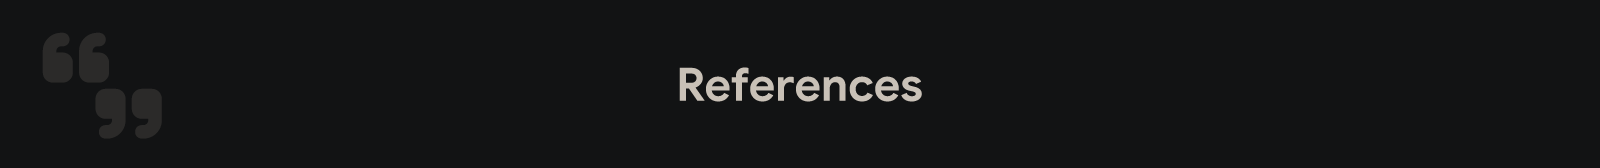

**Data Sources**

- Muñoz-Sabater, J., Dutra, E., Agustí-Panareda, A., Albergel, C., Arduini, G., Balsamo, G., Boussetta, S., Choulga, M., Harrigan, S., Hersbach, H., Martens, B., Miralles, D.G., Piles, M., Rodríguez-Fernández, N.J., Zsoter, E., Buontempo, C., Thépaut, J.-N., 2021. ERA5-Land: a state-of-the-art global reanalysis dataset for land applications. Earth Syst Sci Data 13, 4349–4383. https://doi.org/10.5194/essd-13-4349-2021

- Menne, M.J., Noone, S., Casey, N.W., Dunn, R.H., McNeill, S., Kantor, D., Thorne, P.W., Orcutt, K., Cunningham, S., Risavi, N., 2023. Global Historical Climatology Network-Hourly (GHCNh). https://doi.org/10.25921/jp3d-3v19

**Software & Libraries**

- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., Duchesnay, É., 2011. Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research 12, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

- Waskom, M. L., 2021. seaborn: statistical data visualization. Journal of Open Source Software 6(60), 3021. https://doi.org/10.21105/joss.03021

- Hunter, J. D., 2007. Matplotlib: A 2D Graphics Environment. Computing in Science & Engineering 9(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

- Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., Gérard-Marchant, P., Sheppard, K., Reddy, T., Weckesser, W., Abbasi, H., Gohlke, C., Oliphant, T. E., 2020. Array Programming with NumPy. Nature 585, 357–362. https://doi.org/10.1038/s41586-020-2649-2

- McKinney, W., 2010. Data Structures for Statistical Computing in Python. Proceedings of the 9th Python in Science Conference, 56–61. https://doi.org/10.25080/Majora-92bf1922-00a